# Modern Continuous VLA

Explore **SmolVLA, π₀, and π₀.₅** through eight questions.
Explain each answer using the figure, formula, or source code. Run the supplied experiments where present.

Use a **T4 GPU**. Run the setup cells, then work through the questions in order.
The first run downloads about **0.9 GB** of public model weights.
The notebook includes real SO100 examples. SmolVLA uses pretrained weights;
the π₀ and π₀.₅ experiments use small source-based modules with random or fixed weights.

In [ ]:
import importlib.metadata, importlib.util, os, subprocess, sys
from pathlib import Path
from packaging.requirements import Requirement

os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HUB_DISABLE_XET'] = '1'
ROOT = Path(os.environ.get('SEMINAR06_ROOT', '/content/seminar06' if Path('/content').exists() else './seminar06_runtime')).resolve()
ROOT.mkdir(parents=True, exist_ok=True)
# Preserve the installed scientific stack and matching torch/torchvision pair.
constraints = []
for name in ['torch', 'torchvision', 'numpy', 'pandas', 'matplotlib', 'pillow']:
    try: constraints.append(f'{name}=={importlib.metadata.version(name)}')
    except importlib.metadata.PackageNotFoundError: pass
constraint_file = ROOT / 'preserve_runtime.txt'
constraint_file.write_text('\n'.join(constraints) + '\n')
requirements = [
    'transformers==4.57.1', 'huggingface-hub==0.35.3', 'accelerate==1.12.0',
    'draccus==0.10.0', 'num2words==0.5.14', 'einops==0.8.1',
    'gymnasium==1.2.3', 'deepdiff==8.6.1', 'diffusers==0.35.2',
    'datasets==4.4.2', 'pyserial==3.5', 'jsonlines==4.0.0', 'imageio==2.37.3', 'av==15.1.0',
    'termcolor==3.3.0', 'safetensors>=0.4.3,<1', 'matplotlib>=3.8,<4', 'pandas>=2,<4',
]
pending = []
for spec in requirements:
    req = Requirement(spec)
    try: installed = importlib.metadata.version(req.name)
    except importlib.metadata.PackageNotFoundError: installed = None
    if installed is None or not req.specifier.contains(installed): pending.append(spec)
if pending:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check',
                    '-c', str(constraint_file), *pending], check=True)
try: version = importlib.metadata.version('lerobot')
except importlib.metadata.PackageNotFoundError: version = None
if version != '0.4.4':
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--no-deps', 'lerobot==0.4.4'], check=True)
if importlib.util.find_spec('torchvision') is None:
    raise RuntimeError('Use a fresh Colab T4 runtime with its matching torch/torchvision installation.')
# Check transitive imports in a fresh process before loading weights or starting the exercises.
subprocess.run([sys.executable, '-c',
    'import av; from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy; '
    'from lerobot.policies.pi05.processor_pi05 import Pi05PrepareStateTokenizerProcessorStep; '
    'print("Policy imports ready; PyAV", av.__version__)'], check=True)
print('Environment ready. Select a T4 GPU for the SmolVLA sections.')

In [ ]:
import hashlib, os, urllib.request, zipfile

ASSET_BASE_URL = os.environ.get('SEMINAR06_ASSET_BASE_URL',
    'https://raw.githubusercontent.com/wingrune/multimodal-vla-course/main/06-modern-vla/assets').rstrip('/')
ARCHIVE_NAME = 'seminar06_bundle.zip'
ARCHIVE_SHA256 = 'f331b57098c33b4b5b4385f3ace9702bc2cdcdfd1463c838343c9ea003b13c72'
candidates = [Path('assets') / ARCHIVE_NAME, Path('06-modern-vla/assets') / ARCHIVE_NAME,
              Path('multimodal-vla-course/06-modern-vla/assets') / ARCHIVE_NAME, ROOT / ARCHIVE_NAME]
archive_path = next((p for p in candidates if p.is_file()
    and hashlib.sha256(p.read_bytes()).hexdigest() == ARCHIVE_SHA256), None)
if archive_path is None:
    url = f'{ASSET_BASE_URL}/{ARCHIVE_NAME}'
    print(f'Downloading seminar data and source excerpts: {url}', flush=True)
    archive_path = ROOT / ARCHIVE_NAME
    temporary = archive_path.with_suffix('.zip.part')
    try:
        with urllib.request.urlopen(url, timeout=30) as response, temporary.open('wb') as output:
            while chunk := response.read(128 * 1024):
                output.write(chunk)
        if hashlib.sha256(temporary.read_bytes()).hexdigest() != ARCHIVE_SHA256:
            raise RuntimeError('Archive checksum mismatch')
        temporary.replace(archive_path)
    except Exception as exc:
        temporary.unlink(missing_ok=True)
        raise RuntimeError(f'Could not download {url}. Check the internet connection or put '
                           f'{ARCHIVE_NAME} in assets/ beside the notebook. Details: {exc}') from exc
with zipfile.ZipFile(archive_path) as archive:
    if any(Path(p).is_absolute() or '..' in Path(p).parts for p in archive.namelist()):
        raise RuntimeError('Unexpected archive member path')
    archive.extractall(ROOT)
print('Seminar data and source excerpts are ready.')

In [ ]:
"""Supplied experiments, embedded in both Seminar 06 notebooks.

LeRobot source fragments retain their upstream copyright and Apache-2.0 license
in assets/sources. Small two-stream blocks below are teaching models, not π weights.
"""
from __future__ import annotations
import ast, copy, gc, hashlib, inspect, json, math, os, textwrap, time, types
from collections import Counter
from contextlib import contextmanager
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch
from torch import Tensor, nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# ROOT is set by the notebook's data cell; local scripts can set SEMINAR06_ROOT.
if 'ROOT' not in globals():
    ROOT = Path(os.environ.get('SEMINAR06_ROOT', Path(__file__).parent / 'assets')).resolve()
SOURCE_DIR = ROOT / 'sources'
DATA_DIR = ROOT / 'so100_subset'
MANIFEST = json.loads((DATA_DIR / 'manifest.json').read_text())
ARRAYS = np.load(DATA_DIR / 'windows.npz', allow_pickle=False)
CHANNELS = MANIFEST['channels']
TRAIN = [w for w in MANIFEST['windows'] if w['split'] == 'train']
VALIDATION = [w for w in MANIFEST['windows'] if w['split'] == 'validation']
assert set(MANIFEST['train_episodes']).isdisjoint(MANIFEST['validation_episodes'])
torch.manual_seed(6)
torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')


def source_fragment(filename, name, owner=None):
    """Read a pinned source fragment with its original line numbers."""
    source = (SOURCE_DIR / filename).read_text()
    tree = ast.parse(source)
    nodes = tree.body if owner is None else next(n for n in tree.body if isinstance(n, ast.ClassDef) and n.name == owner).body
    node = next(n for n in nodes if isinstance(n, (ast.FunctionDef, ast.ClassDef)) and n.name == name)
    lines = source.splitlines()
    code = textwrap.dedent('\n'.join(lines[node.lineno-1:node.end_lineno]))
    return code, node.lineno


def show_source(filename, name, owner=None, max_lines=45):
    code, line = source_fragment(filename, name, owner)
    lines = code.splitlines()
    display_text = '\n'.join(f'{line+i:4d}  {s}' for i, s in enumerate(lines[:max_lines]))
    print(display_text)
    if len(lines) > max_lines:
        print(f'… {len(lines)-max_lines} more lines in {filename}')


def load_fragment(filename, name, owner=None):
    code, _ = source_fragment(filename, name, owner)
    scope = dict(globals())
    exec(compile(code, str(SOURCE_DIR / filename), 'exec'), scope)
    return scope[name]


get_safe_dtype = load_fragment('modeling_pi0.py', 'get_safe_dtype')
create_sinusoidal_pos_embedding = load_fragment('modeling_pi0.py', 'create_sinusoidal_pos_embedding')
pi_mask = load_fragment('modeling_pi0.py', 'make_att_2d_masks')
PiGemmaRMSNorm = load_fragment('pi_gemma.py', 'PiGemmaRMSNorm')
_gated_residual = load_fragment('pi_gemma.py', '_gated_residual')


def shape_tree(x):
    if torch.is_tensor(x): return tuple(x.shape)
    if isinstance(x, (list, tuple)): return [shape_tree(y) for y in x]
    if isinstance(x, dict): return {k: shape_tree(v) for k, v in x.items()}
    return type(x).__name__


@contextmanager
def trace_modules(modules):
    rows, handles = [], []
    for name, module in modules.items():
        def hook(mod, inputs, kwargs, outputs, label=name):
            rows.append({'module': label, 'input': str(shape_tree(inputs if inputs else kwargs)), 'output': str(shape_tree(outputs))})
        handles.append(module.register_forward_hook(hook, with_kwargs=True))
    try: yield rows
    finally:
        for h in handles: h.remove()


@contextmanager
def trace_methods(methods):
    """Capture tensor shapes at the model boundaries shown in the paper figure."""
    captured, originals = {}, []
    for label, obj, name in methods:
        original = getattr(obj, name)
        originals.append((obj, name, original))
        def wrapped(*args, _fn=original, _label=label, **kwargs):
            result = _fn(*args, **kwargs)
            if _label not in captured:
                captured[_label] = {'input': shape_tree(args if args else kwargs),
                                    'output': shape_tree(result)}
            return result
        setattr(obj, name, wrapped)
    try:
        yield captured
    finally:
        for obj, name, original in originals:
            setattr(obj, name, original)


def fixed_noise(shape, device=DEVICE, seed=6):
    return torch.randn(shape, generator=torch.Generator(device=device).manual_seed(seed), device=device)


def fetch_file(url, dest):
    import requests
    dest = Path(dest)
    if dest.exists(): return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    part = dest.with_suffix(dest.suffix + '.part')
    with requests.get(url, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        with part.open('wb') as out:
            for chunk in response.iter_content(1024*1024): out.write(chunk)
    part.replace(dest)
    return dest


MODEL_REV = '5e8d12a6e2975b0e5e5fce7c8caf47c371d257b6'
BACKBONE_REV = '7b375e1b73b11138ff12fe22c8f2822d8fe03467'
BACKBONE_FILES = ['added_tokens.json', 'chat_template.json', 'config.json', 'generation_config.json',
                  'preprocessor_config.json', 'processor_config.json', 'special_tokens_map.json',
                  'tokenizer.json', 'tokenizer_config.json', 'vocab.json']


def model_files():
    root = Path(os.environ.get('SEMINAR06_MODEL_ROOT', ROOT / 'models'))
    specs = [('lerobot/smolvla_base', MODEL_REV, 'policy', ['config.json', 'model.safetensors']),
             ('HuggingFaceTB/SmolVLM2-500M-Video-Instruct', BACKBONE_REV, 'backbone', BACKBONE_FILES)]
    for repo, rev, folder, files in specs:
        for f in files:
            dest = root / folder / f
            if not dest.exists(): print(f'Downloading {repo}/{f}', flush=True)
            fetch_file(f'https://huggingface.co/{repo}/resolve/{rev}/{f}', dest)
    return root


class SmolExperiment:
    def __init__(self):
        from lerobot.configs.policies import PreTrainedConfig
        from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy, make_att_2d_masks
        from safetensors.torch import load_model
        files = model_files()
        config = PreTrainedConfig.from_pretrained(str(files / 'policy'))
        # Base policy weights already contain the VLM; avoid downloading/loading it twice.
        config.load_vlm_weights = False
        config.vlm_model_name = str(files / 'backbone')
        config.device = str(DEVICE)
        config.empty_cameras = 1
        self.policy = SmolVLAPolicy(config)
        missing, unexpected = load_model(self.policy, str(files / 'policy/model.safetensors'), strict=False)
        if missing or unexpected: raise RuntimeError(f'Checkpoint mismatch: {missing}, {unexpected}')
        self.policy.to(device=DEVICE, dtype=torch.float32).eval()
        self.core = self.policy.model
        self.mask_fn = make_att_2d_masks
        self.calls = Counter()
        self.noise = fixed_noise((1, config.chunk_size, config.max_action_dim))
        self.time = torch.tensor([0.6], device=DEVICE)
        self.batch = self.make_batch(TRAIN[0])
        print(f'SmolVLA: {sum(p.numel() for p in self.policy.parameters())/1e6:.0f}M parameters; {DEVICE}')

    def make_batch(self, window):
        tokenizer = self.core.vlm_with_expert.processor.tokenizer
        tokens = tokenizer(window['instruction'] + '\n', return_tensors='pt', truncation=True,
                           padding='max_length', max_length=self.policy.config.tokenizer_max_length)
        batch = {'observation.language.tokens': tokens.input_ids.to(DEVICE),
                 'observation.language.attention_mask': tokens.attention_mask.bool().to(DEVICE)}
        for feature, suffix in [('observation.state', 'state'), ('action', 'actions')]:
            a = ARRAYS[window['key'] + '_' + suffix]
            stats = MANIFEST['stats'][feature]
            normalized = (a - np.array(stats['mean'])) / np.array(stats['std'])
            batch[feature] = torch.as_tensor(normalized, dtype=torch.float32, device=DEVICE)[None]
        for camera, view in [('camera1', 'top'), ('camera2', 'wrist')]:
            a = np.array(Image.open(DATA_DIR / window['images'][view]['file']).convert('RGB'), copy=True)
            batch['observation.images.' + camera] = torch.tensor(a, device=DEVICE).permute(2, 0, 1)[None].float()/255
        return batch

    def inputs(self, batch):
        images, masks = self.policy.prepare_images(batch)
        return images, masks, batch['observation.language.tokens'], batch['observation.language.attention_mask'], self.policy.prepare_state(batch)

    @torch.no_grad()
    def prediction_trace(self):
        vlm = self.core.vlm_with_expert
        methods = [('image', vlm, 'embed_image'), ('language', vlm, 'embed_language_tokens'),
                   ('prefix', self.core, 'embed_prefix'), ('suffix', self.core, 'embed_suffix'),
                   ('velocity', self.core, 'denoise_step')]
        with trace_methods(methods) as captured, trace_modules({'state': self.core.state_proj}) as state_rows:
            chunk = self.policy.predict_action_chunk(self.batch, noise=self.noise.clone())
        self.chunk = chunk.detach().cpu()
        state_shape = ast.literal_eval(state_rows[0]['input'])[0]
        state_width = self.core.state_proj.out_features
        rows = [
            {'row': 'A', 'Location in Figure 1': 'Camera pictures → left VLM tower',
             'What the tensor represents': 'Visual features from one camera',
             'Tensor shape': str(captured['image']['output'])},
            {'row': 'B', 'Location in Figure 1': 'Task text → left VLM tower',
             'What the tensor represents': 'Instruction-token embeddings',
             'Tensor shape': str(captured['language']['output'])},
            {'row': 'C', 'Location in Figure 1': 'State box → left VLM tower',
             'What the tensor represents': 'One projected robot-state token',
             'Tensor shape': f'{state_shape} → (1, 1, {state_width})'},
            {'row': 'D', 'Location in Figure 1': 'Left VLM tower: A–C combined at its input',
             'What the tensor represents': 'Combined image/text/state prefix entering the VLM',
             'Tensor shape': str(captured['prefix']['output'][0])},
            {'row': 'E', 'Location in Figure 1': 'Noisy Actions box → right expert tower',
             'What the tensor represents': 'Noisy action embeddings combined with flow time',
             'Tensor shape': str(captured['suffix']['output'][0])},
            {'row': 'F', 'Location in Figure 1': 'Inside Action Expert, before the top output arrow',
             'What the tensor represents': 'Predicted velocity for one denoising update',
             'Tensor shape': str(captured['velocity']['output'])},
            {'row': 'G', 'Location in Figure 1': 'Top action sequence [aₜ, …, aₜ₊H]',
             'What the tensor represents': 'Action chunk after integration and unpadding',
             'Tensor shape': str(tuple(chunk.shape))},
        ]
        self.trace_table = pd.DataFrame(rows)
        with pd.option_context('display.max_colwidth', None, 'display.max_columns', None):
            display(self.trace_table)
        print('Shapes: (batch, positions, feature width). Row C pads six state values to 32, then projects them into one token.')
        print('Row F has 32 internal action channels; row G keeps the six channels of this robot.')
        print('The figure omits flow time, the velocity projection, and the integration loop. F is an intermediate result; G is the final output.')
        stats = MANIFEST['stats']['action']
        denorm = self.chunk[0].numpy()*np.array(stats['std']) + np.array(stats['mean'])
        plt.figure(figsize=(7, 2.5))
        plt.plot(np.arange(50)/MANIFEST['fps'], denorm[:, 0], label='predicted shoulder target')
        plt.plot(np.arange(50)/MANIFEST['fps'], ARRAYS[TRAIN[0]['key']+'_actions'][:, 0], label='recorded target')
        plt.title('Row G: one channel of the final action chunk')
        plt.xlabel('Time within chunk (s)'); plt.ylabel('degrees'); plt.legend(); plt.tight_layout(); plt.show()
        return chunk

    @torch.no_grad()
    def supervision_probe(self):
        self.policy.eval()
        action = self.policy.prepare_action(self.batch)
        tau = self.time[:, None, None]
        delta = torch.zeros_like(action)
        delta[:, :, 0] = 0.5  # hypothetical change, in normalized robot-action units
        alternate_action = action + delta
        alternate_noise = self.noise - (1 - tau) / tau * delta
        x = (1 - tau) * action + tau * self.noise
        alternate_x = (1 - tau) * alternate_action + tau * alternate_noise
        velocity = self.recomputed_velocity(self.batch, x, self.time)
        alternate_velocity = self.recomputed_velocity(self.batch, alternate_x, self.time)
        target = self.noise - action
        alternate_target = alternate_noise - alternate_action
        torch.testing.assert_close(x, alternate_x, rtol=1e-5, atol=1e-6)
        torch.testing.assert_close(velocity, alternate_velocity, rtol=1e-4, atol=1e-4)
        torch.testing.assert_close(alternate_target - target, -delta / tau, rtol=1e-5, atol=1e-6)
        # Same elementwise MSE as the core objective, averaged over its padded tensor.
        losses = [(velocity - target).square().mean().item(),
                  (alternate_velocity - alternate_target).square().mean().item()]
        display(pd.DataFrame([
            {'quantity': 'Noisy expert input x_tau', 'maximum change': (x-alternate_x).abs().max().item()},
            {'quantity': 'Predicted velocity v', 'maximum change': (velocity-alternate_velocity).abs().max().item()},
            {'quantity': 'Supervised velocity target u', 'maximum change': (target-alternate_target).abs().max().item()},
        ]))
        display(pd.DataFrame({'hypothetical label': ['original A', 'alternative A + delta'],
                              'mean squared velocity error': losses}))

    @torch.no_grad()
    def prefix(self, batch):
        self.calls['prefix_embeddings'] += 1
        return self.core.embed_prefix(*self.inputs(batch))

    @torch.no_grad()
    def prefill(self, batch):
        prefix, pad, att = self.prefix(batch)
        self.calls['prefix_transformer'] += 1
        _, cache = self.core.vlm_with_expert.forward(
            attention_mask=self.mask_fn(pad, att), position_ids=torch.cumsum(pad, dim=1)-1,
            past_key_values=None, inputs_embeds=[prefix, None], use_cache=True, fill_kv_cache=True)
        return pad, cache

    @torch.no_grad()
    def cached_velocity(self, bundle, x, timestep):
        pad, cache = bundle
        self.calls['expert'] += 1
        return self.core.denoise_step(pad, cache, x, timestep)

    @torch.no_grad()
    def recomputed_velocity(self, batch, x, timestep):
        prefix, pp, pa = self.prefix(batch)
        suffix, sp, sa = self.core.embed_suffix(x, timestep)
        pad, att = torch.cat([pp, sp], 1), torch.cat([pa, sa], 1)
        self.calls['prefix_transformer'] += 1; self.calls['expert'] += 1
        (_, out), _ = self.core.vlm_with_expert.forward(
            attention_mask=self.mask_fn(pad, att), position_ids=torch.cumsum(pad, dim=1)-1,
            past_key_values=None, inputs_embeds=[prefix, suffix], use_cache=False, fill_kv_cache=False)
        return self.core.action_out_proj(out[:, -self.policy.config.chunk_size:].float())

    @torch.no_grad()
    def cache_comparison(self):
        self.policy.eval()
        probes = [(self.noise, torch.tensor([0.8], device=DEVICE)),
                  (self.noise*.6, torch.tensor([0.3], device=DEVICE))]
        self.calls.clear(); bundle = self.prefill(self.batch)
        cached = torch.stack([self.cached_velocity(bundle, x, t) for x, t in probes])
        cache_counts = dict(self.calls)
        self.calls.clear()
        recomputed = torch.stack([self.recomputed_velocity(self.batch, x, t) for x, t in probes])
        counts = pd.DataFrame([{'mode': 'cached', **cache_counts}, {'mode': 'recomputed', **dict(self.calls)}])
        display(counts)
        self.bundle = bundle
        return cached, recomputed, counts

    @torch.no_grad()
    def cache_latency_probe(self):
        self.policy.eval()
        def synchronize():
            if DEVICE.type == 'cuda': torch.cuda.synchronize()
        def milliseconds(fn, repeats=5):
            for _ in range(2): fn()
            samples = []
            for _ in range(repeats):
                synchronize(); start = time.perf_counter()
                result = fn()
                synchronize(); samples.append(1000 * (time.perf_counter() - start))
                del result
            return float(np.median(samples))
        self.bundle = self.prefill(self.batch)
        x, t = self.noise, self.time
        p = milliseconds(lambda: self.prefill(self.batch))
        c = milliseconds(lambda: self.cached_velocity(self.bundle, x, t))
        r = milliseconds(lambda: self.recomputed_velocity(self.batch, x, t))
        display(pd.DataFrame({'operation': ['P: build prefix K/V', 'C: expert with cached K/V',
                                           'R: full prefix + expert'], 'median ms': [p, c, r]}))
        def evaluate(n, use_cache):
            bundle = self.prefill(self.batch) if use_cache else None
            for i in range(n):
                probe_x = self.noise if i % 2 == 0 else self.noise * 0.6
                probe_t = self.time.new_tensor([0.8 if i % 2 == 0 else 0.3])
                if use_cache: self.cached_velocity(bundle, probe_x, probe_t)
                else: self.recomputed_velocity(self.batch, probe_x, probe_t)
        rows = []
        for n in [1, 2, 10]:
            rows.append({'expert evaluations N': n, 'estimated cached ms': p+n*c,
                         'estimated recomputed ms': n*r,
                         'measured cached ms': milliseconds(lambda: evaluate(n, True), repeats=3),
                         'measured recomputed ms': milliseconds(lambda: evaluate(n, False), repeats=3)})
        display(pd.DataFrame(rows))
        print('Median synchronized wall times after warm-up; repeated forward probes, not complete robot latency.')
        return p, c, r

    @torch.no_grad()
    def changed_state(self):
        changed = {k: v.clone() for k, v in self.batch.items()}
        changed['observation.state'][:, 0] += 0.5  # half a train standard deviation
        t = torch.tensor([0.6], device=DEVICE)
        stale = self.cached_velocity(self.bundle, self.noise, t)
        fresh_bundle = self.prefill(changed)
        fresh = self.cached_velocity(fresh_bundle, self.noise, t)
        _, a = self.bundle; _, b = fresh_bundle
        kv_delta = max((a[k][name]-b[k][name]).abs().max().item() for k in a for name in ['key_states', 'value_states'])
        print(f'Max prefix K/V change: {kv_delta:.6g}')
        return stale, fresh, kv_delta

    @torch.no_grad()
    def partial_state_cache_probe(self, patch_state_kv):
        self.policy.eval()
        old_bundle = self.prefill(self.batch)
        changed = dict(self.batch)
        changed['observation.state'] = self.batch['observation.state'].clone()
        changed['observation.state'][:, 0] += 0.5
        fresh_bundle = self.prefill(changed)
        _, pad, att = self.core.embed_prefix(*self.inputs(self.batch))
        state_positions = torch.nonzero(att[0], as_tuple=False).flatten()
        assert len(state_positions) == 1
        state_position = state_positions.item()
        image_text = pad[0].clone(); image_text[state_position] = False
        mask = self.mask_fn(pad, att)[0]
        print('Image/text queries can read state:', bool(mask[image_text, state_position].any()))
        print('State query can read image/text:', bool(mask[state_position, image_text].any()))
        old_cache, fresh_cache = old_bundle[1], fresh_bundle[1]
        snapshots = {k: {name: value.clone() for name, value in layer.items()}
                     for k, layer in old_cache.items()}
        rows, patched, last_only = [], {}, {}
        last_layer = max(old_cache)
        for k, layer in old_cache.items():
            patched[k], last_only[k] = {}, {}
            for name, value in layer.items():
                new_value = fresh_cache[k][name]
                delta = (value-new_value).abs()
                rows.append({'layer': k, 'tensor': name,
                             'image/text max change': delta[:, image_text].max().item(),
                             'state max change': delta[:, state_position].max().item()})
                replacement = patch_state_kv(value, new_value, state_position)
                patched[k][name] = replacement
                last_only[k][name] = replacement if k == last_layer else value
                torch.testing.assert_close(value, snapshots[k][name], rtol=0, atol=0)
                torch.testing.assert_close(replacement[:, state_position], new_value[:, state_position])
                keep = torch.ones(value.shape[1], dtype=torch.bool, device=value.device)
                keep[state_position] = False
                torch.testing.assert_close(replacement[:, keep], value[:, keep], rtol=0, atol=0)
        display(pd.DataFrame(rows))
        fresh = self.cached_velocity(fresh_bundle, self.noise, self.time)
        stale = self.cached_velocity(old_bundle, self.noise, self.time)
        hybrid = self.cached_velocity((fresh_bundle[0], patched), self.noise, self.time)
        last = self.cached_velocity((fresh_bundle[0], last_only), self.noise, self.time)
        display(pd.DataFrame([
            {'cache': label, 'max velocity error vs fresh': (velocity-fresh).abs().max().item()}
            for label, velocity in [('old cache', stale), ('state replaced in every layer', hybrid),
                                    ('state replaced in last layer only', last)]
        ]))
        torch.testing.assert_close(hybrid, fresh, rtol=1e-4, atol=1e-4)
        print('Fresh K/V were computed in full to test equivalence; this probe does not implement a faster state refresh.')
        self.bundle = old_bundle
        return stale, fresh

    def short_finetune(self, steps=20):
        if not 1 <= steps <= 500: raise ValueError('Use 1–500 optimizer updates.')
        # Drop inference caches before any parameter updates.
        self.bundle = None
        self.policy.train()
        selected = {}
        for group, prefix in [('VLM', 'model.vlm_with_expert.vlm.'),
                              ('expert', 'model.vlm_with_expert.lm_expert.'),
                              ('state_proj', 'model.state_proj.'), ('action_out_proj', 'model.action_out_proj.')]:
            selected[group] = next((n, p) for n, p in self.policy.named_parameters() if n.startswith(prefix) and n.endswith('weight'))
        before = {g: p.detach().clone() for g, (_, p) in selected.items()}
        optimizer = torch.optim.AdamW([p for p in self.policy.parameters() if p.requires_grad], lr=1e-4,
                                      betas=(.9, .95), weight_decay=1e-10)
        batches = [self.make_batch(w) for w in TRAIN]
        val_batch = self.make_batch(VALIDATION[0])
        val_noise = fixed_noise(self.noise.shape, seed=17)
        def validation_loss():
            self.policy.eval()
            with torch.no_grad(): value = self.policy(val_batch, noise=val_noise, time=self.time)[0].item()
            self.policy.train()
            return value
        initial_val = validation_loss()
        if DEVICE.type == 'cuda': torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
        start = time.perf_counter(); log = []; grad_norms = {}
        for step in range(steps):
            optimizer.zero_grad(set_to_none=True)
            loss, _ = self.policy(batches[step % len(batches)], noise=fixed_noise(self.noise.shape, seed=100+step),
                                  time=self.core.sample_time(1, DEVICE))
            loss.backward()
            if step == 0:
                grad_norms = {g: None if p.grad is None else p.grad.norm().item() for g, (_, p) in selected.items()}
            torch.nn.utils.clip_grad_norm_([p for p in self.policy.parameters() if p.requires_grad], 10)
            optimizer.step()
            log.append({'update': step+1, 'train_flow_loss': loss.item()})
            if step == 0 or (step+1) % 5 == 0: print(f'Update {step+1}/{steps}: {loss.item():.4f}', flush=True)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        elapsed = time.perf_counter()-start
        audit = pd.DataFrame([{'group': g, 'example_parameter': n, 'trainable': p.requires_grad,
                               'gradient_norm_first_update': grad_norms[g],
                               'max_parameter_change': (p.detach()-before[g]).abs().max().item()}
                              for g, (n, p) in selected.items()])
        final_val = validation_loss()
        result = {'updates': steps, 'seconds_per_update': elapsed/steps,
                  'peak_allocated_GiB': torch.cuda.max_memory_allocated()/2**30 if DEVICE.type == 'cuda' else None,
                  'validation_before': initial_val, 'validation_after': final_val}
        display(audit); display(pd.DataFrame([result]))
        pd.DataFrame(log).plot(x='update', y='train_flow_loss', figsize=(6, 2.5)); plt.ylabel('flow loss'); plt.tight_layout(); plt.show()
        out = ROOT / 'runs'; out.mkdir(exist_ok=True)
        audit.to_csv(out/'smolvla_parameter_audit.csv', index=False)
        pd.DataFrame(log).to_csv(out/'smolvla_training.csv', index=False)
        (out/'smolvla_result.json').write_text(json.dumps(result, indent=2))
        # Save exactly the trainable adaptation; the frozen base stays pinned.
        torch.save({n: p.detach().cpu() for n, p in self.policy.named_parameters() if p.requires_grad}, out/'smolvla_adaptation.pt')
        self.policy.eval()
        del optimizer, batches, val_batch, before
        gc.collect()
        return audit, result


class TinySuffix(nn.Module):
    """Execute the real π embed_suffix methods at small dimensions, with random weights."""
    def __init__(self, kind, horizon=4, width=16):
        super().__init__(); self.kind = kind
        self.config = SimpleNamespace(min_period=.004, max_period=4., chunk_size=horizon)
        self.action_in_proj = nn.Linear(6, width)
        if kind == 'pi0':
            self.state_proj = nn.Linear(6, width)
            self.action_time_mlp_in = nn.Linear(2*width, width)
            self.action_time_mlp_out = nn.Linear(width, width)
            method = load_fragment('modeling_pi0.py', 'embed_suffix', 'PI0Pytorch')
        else:
            self.time_mlp_in = nn.Linear(width, width); self.time_mlp_out = nn.Linear(width, width)
            method = load_fragment('modeling_pi05.py', 'embed_suffix', 'PI05Pytorch')
        self.embed_suffix = types.MethodType(method, self)

    @staticmethod
    def _apply_checkpoint(fn, *args): return fn(*args)


class Tower(nn.Module):
    def __init__(self, width, attention_width=8):
        super().__init__()
        self.q = nn.Linear(width, attention_width, bias=False)
        self.k = nn.Linear(width, attention_width, bias=False)
        self.v = nn.Linear(width, attention_width, bias=False)
        self.out = nn.Linear(attention_width, width, bias=False)
        self.mlp = nn.Sequential(nn.Linear(width, 2*width), nn.SiLU(), nn.Linear(2*width, width))


class TinyPi0(nn.Module):
    """A small two-stream block using π0's suffix and freeze methods.

    Q/K/V concatenation follows PaliGemmaWithExpertModel; learned vision/text
    inputs are placeholders, not PaliGemma features. No pretrained π0 weights.
    """
    def __init__(self, vision_freeze=False, expert_only=False):
        super().__init__()
        self.paligemma = nn.Module()
        self.paligemma.vision_tower = nn.Linear(3, 24)
        self.paligemma.text_embedding = nn.Embedding(32, 24)
        self.paligemma.language_model = Tower(24)
        self.expert = Tower(16)
        self.suffix = TinySuffix('pi0')
        self.action_out_proj = nn.Linear(16, 6)
        self.freeze_vision_encoder = vision_freeze; self.train_expert_only = expert_only
        self._set_requires_grad = types.MethodType(load_fragment('modeling_pi0.py', '_set_requires_grad', 'PaliGemmaWithExpertModel'), self)
        self._set_requires_grad()

    def prefix(self, image_features, text_ids):
        return torch.cat([self.paligemma.vision_tower(image_features), self.paligemma.text_embedding(text_ids)], dim=1)

    def forward(self, data, attention_fn, prefix_leaf=None):
        prefix = self.prefix(data['image'], data['text']) if prefix_leaf is None else prefix_leaf
        suffix, sp, sa, _ = self.suffix.embed_suffix(data['state'], data['noisy_actions'], data['time'])
        pp = torch.ones(prefix.shape[:2], dtype=torch.bool)
        pa = torch.zeros_like(pp)
        mask = pi_mask(torch.cat([pp, sp], 1), torch.cat([pa, sa], 1))
        a, b = self.paligemma.language_model, self.expert
        q = torch.cat([a.q(prefix), b.q(suffix)], dim=1)
        k = torch.cat([a.k(prefix), b.k(suffix)], dim=1)
        v = torch.cat([a.v(prefix), b.v(suffix)], dim=1)
        joined = attention_fn(q, k, v, mask)
        po, so = joined[:, :prefix.shape[1]], joined[:, prefix.shape[1]:]
        po = prefix + a.out(po); po = po + a.mlp(po)
        so = suffix + b.out(so); so = so + b.mlp(so)
        actions = self.action_out_proj(so[:, -4:])
        return actions, {'prefix_input': prefix, 'suffix_input': suffix, 'prefix_output': po,
                         'suffix_output': so, 'q': q, 'k': k, 'v': v, 'mask': mask}


def make_tiny_data():
    g = torch.Generator().manual_seed(31)
    return {'image': torch.randn(1, 2, 3, generator=g), 'text': torch.tensor([[1, 4, 7]]),
            'state': torch.randn(1, 6, generator=g), 'noisy_actions': torch.randn(1, 4, 6, generator=g),
            'time': torch.tensor([.6]), 'target': torch.randn(1, 4, 6, generator=g)}


TINY_DATA = make_tiny_data()
torch.manual_seed(18)
TINY_PI0 = TinyPi0()


def suffix_location_probe():
    pi0 = TINY_PI0
    changed = {k: v.clone() for k, v in TINY_DATA.items()}; changed['state'][:, 0] += .5
    with torch.no_grad():
        p0, p1 = pi0.prefix(TINY_DATA['image'], TINY_DATA['text']), pi0.prefix(changed['image'], changed['text'])
        a0 = pi0.suffix.embed_suffix(TINY_DATA['state'], TINY_DATA['noisy_actions'], TINY_DATA['time'])[0]
        a1 = pi0.suffix.embed_suffix(changed['state'], changed['noisy_actions'], changed['time'])[0]
    display(pd.DataFrame([{'tensor': 'image/text prefix', 'shape': str(tuple(p0.shape)), 'max_change': (p1-p0).abs().max().item()},
                          {'tensor': 'state suffix token', 'shape': str(tuple(a0[:, :1].shape)), 'max_change': (a1[:, :1]-a0[:, :1]).abs().max().item()},
                          {'tensor': 'action/time suffix', 'shape': str(tuple(a0[:, 1:].shape)), 'max_change': (a1[:, 1:]-a0[:, 1:]).abs().max().item()}]))


def reference_attention(q, k, v, mask):
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])
    return scores.masked_fill(~mask, -torch.inf).softmax(dim=-1) @ v


@torch.no_grad()
def attention_routing_probe():
    model = TINY_PI0.eval()
    baseline, trace = model(TINY_DATA, reference_attention)
    p = trace['prefix_input'].shape[1]
    mask = trace['mask'][0]
    labels = ['image 0', 'image 1', 'text 0', 'text 1', 'text 2', 'state', 'A0', 'A1', 'A2', 'A3']
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.imshow(mask.float().cpu(), vmin=0, vmax=1, cmap='Blues')
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel('Key/value token being read'); ax.set_ylabel('Query token doing the reading')
    ax.set_title('π₀ attention mask: blue = allowed, white = blocked')
    for boundary in [p-0.5, p+0.5]:
        ax.axhline(boundary, color='black', linewidth=1)
        ax.axvline(boundary, color='black', linewidth=1)
    plt.tight_layout(); plt.show()
    variants = {}
    for label, field, position in [('state changed', 'state', (0, 0)),
                                   ('last noisy action changed', 'noisy_actions', (0, -1, 0))]:
        data = {k: v.clone() for k, v in TINY_DATA.items()}
        data[field][position] += 0.5
        variants[label] = data
    def bidirectional(q, k, v, allowed):
        # Counterfactual: remove group restrictions. This fixture has no padding.
        return reference_attention(q, k, v, torch.ones_like(allowed))
    rows = []
    for mode, fn in [('π₀ mask', reference_attention), ('bidirectional (modified)', bidirectional)]:
        base_velocity, base_trace = model(TINY_DATA, fn)
        for label, data in variants.items():
            velocity, changed = model(data, fn)
            prefix_delta = (changed['prefix_output']-base_trace['prefix_output']).abs().max().item()
            state_delta = (changed['suffix_output'][:, :1]-base_trace['suffix_output'][:, :1]).abs().max().item()
            first_action_delta = (changed['suffix_output'][:, 1]-base_trace['suffix_output'][:, 1]).abs().max().item()
            first_velocity_delta = (velocity[:, 0]-base_velocity[:, 0]).abs().max().item()
            rows.append({'mask': mode, 'intervention': label,
                         'VLM output change': prefix_delta, 'state output change': state_delta,
                         'first action output change': first_action_delta,
                         'first velocity change': first_velocity_delta})
            if mode == 'π₀ mask':
                torch.testing.assert_close(changed['prefix_output'], base_trace['prefix_output'], rtol=0, atol=0)
                if label == 'last noisy action changed':
                    torch.testing.assert_close(changed['suffix_output'][:, :1], base_trace['suffix_output'][:, :1], rtol=0, atol=0)
                    assert first_velocity_delta > 1e-7
            else:
                assert prefix_delta > 1e-7
    display(pd.DataFrame(rows))
    print('All output changes are measured AFTER attention, residual updates, and the MLP in one small block.')
    print('Weights are random teaching substitutes; mask and suffix rules come from the pinned π₀ source.')


def attention_probe(attention_fn):
    output, trace = TINY_PI0(TINY_DATA, attention_fn)
    expected, _ = TINY_PI0(TINY_DATA, reference_attention)
    torch.testing.assert_close(output, expected)
    display(pd.DataFrame([{'stream': 'VLM', 'hidden_width': 24, 'QKV_width': 8,
                          'parameters': sum(p.numel() for p in TINY_PI0.paligemma.language_model.parameters())},
                         {'stream': 'expert', 'hidden_width': 16, 'QKV_width': 8,
                          'parameters': sum(p.numel() for p in TINY_PI0.expert.parameters())}]))
    print('Joint Q/K/V:', tuple(trace['q'].shape), tuple(trace['k'].shape), tuple(trace['v'].shape))
    print('VLM and expert Q weights share storage:', TINY_PI0.paligemma.language_model.q.weight.data_ptr() == TINY_PI0.expert.q.weight.data_ptr())
    return output.detach(), trace


@torch.no_grad()
def split_attention_probe(mix_group_outputs):
    model = TINY_PI0.eval()
    _, trace = model(TINY_DATA, reference_attention)
    p = trace['prefix_input'].shape[1]
    q, k, v = trace['q'][:, -4:], trace['k'], trace['v']
    allowed = trace['mask'][:, -4:]
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])
    scores = scores.masked_fill(~allowed, -torch.inf)
    # Use one common shift for numerical stability; the ratio of group masses is unchanged.
    weights = (scores - scores.max(dim=-1, keepdim=True).values).exp()
    z_vlm = weights[:, :, :p].sum(dim=-1, keepdim=True)
    z_expert = weights[:, :, p:].sum(dim=-1, keepdim=True)
    vlm_output = (weights[:, :, :p] / z_vlm) @ v[:, :p]
    expert_output = (weights[:, :, p:] / z_expert) @ v[:, p:]
    joint = reference_attention(q, k, v, allowed)
    mixed = mix_group_outputs(vlm_output, expert_output, z_vlm, z_expert)
    torch.testing.assert_close(mixed, joint, rtol=1e-5, atol=1e-6)
    rows = []
    for label, value in [('sum of separate outputs', vlm_output+expert_output),
                         ('equal average', 0.5*(vlm_output+expert_output)),
                         ('your mass-weighted mixture', mixed)]:
        rows.append({'replacement': label, 'max attention-output error vs joint': (value-joint).abs().max().item()})
    display(pd.DataFrame(rows))
    display(pd.DataFrame({'action query': range(4), 'VLM group mass Z_vlm': z_vlm.flatten().tolist(),
                          'expert group mass Z_expert': z_expert.flatten().tolist(),
                          'VLM share of joint attention': (z_vlm/(z_vlm+z_expert)).flatten().tolist()}))
    print('The expert group contains both the state token and noisy-action tokens.')
    print('Outputs are attention weighted sums before output projection, residuals, and MLP.')


def parameter_group(name):
    if name.startswith('paligemma.vision_tower.'): return 'vision'
    if name.startswith('paligemma.'): return 'VLM text'
    if name.startswith('expert.'): return 'expert'
    return 'state/action/time projections'


def freeze_comparison(active_parameters):
    rows = []
    initial = copy.deepcopy(TINY_PI0.state_dict())
    for name, vf, eo in [('vision freeze', True, False), ('expert-only', False, True)]:
        model = TinyPi0(vf, eo); model.load_state_dict(initial)
        params = list(active_parameters(model))
        assert {id(p) for p in params} == {id(p) for p in model.parameters() if p.requires_grad}, 'Select exactly the trainable parameters.'
        optimizer = torch.optim.SGD(params, lr=.05)
        loss = F.mse_loss(model(TINY_DATA, reference_attention)[0], TINY_DATA['target'])
        optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
        for group in ['vision', 'VLM text', 'expert', 'state/action/time projections']:
            items = [(n, p) for n, p in model.named_parameters() if parameter_group(n) == group]
            rows.append({'mode': name, 'group': group,
                         'trainable_parameters': sum(p.numel() for _, p in items if p.requires_grad),
                         'gradient_norm': sum(0. if p.grad is None else p.grad.square().sum().item() for _, p in items)**.5,
                         'max_parameter_change': max((p.detach()-initial[n]).abs().max().item() for n, p in items)})
    result = pd.DataFrame(rows); display(result)
    return result


def conditioning_derivative_probe():
    model = TinyPi0(expert_only=True); model.load_state_dict(TINY_PI0.state_dict())
    results = []
    for detach in [False, True]:
        model.zero_grad(set_to_none=True)
        prefix = model.prefix(TINY_DATA['image'], TINY_DATA['text']).detach().requires_grad_(True)
        output, _ = model(TINY_DATA, reference_attention, prefix_leaf=prefix.detach() if detach else prefix)
        loss = F.mse_loss(output, TINY_DATA['target']); loss.backward()
        results.append({'detach': detach, 'loss': loss.item(),
                        'prefix_gradient_norm': None if prefix.grad is None else prefix.grad.norm().item(),
                        'VLM_weight_gradient': model.paligemma.language_model.q.weight.grad is not None,
                        'expert_gradient_norm': model.expert.q.weight.grad.norm().item()})
    result = pd.DataFrame(results); display(result)
    return result


@torch.no_grad()
def discrete_state_continuous_action_probe():
    from lerobot.policies.pi05.processor_pi05 import Pi05PrepareStateTokenizerProcessorStep
    from lerobot.processor.core import TransitionKey
    processor = Pi05PrepareStateTokenizerProcessorStep(max_state_dim=32)
    # Normalized teaching states; dyadic values make the bin-boundary test exact.
    bin_width = 2 / 256
    boundary = 0.25
    pairs = [('inside one bin', boundary + bin_width/4, boundary + bin_width/2),
             ('across a bin boundary', boundary - bin_width/8, boundary + bin_width/8)]
    with torch.random.fork_rng():
        torch.manual_seed(61)
        expert = TinySuffix('pi05')
    rows, prompts = [], []
    for label, before, after in pairs:
        pair_prompts, pair_embeddings, bins = [], [], []
        for value in [before, after]:
            state = torch.zeros(1, 6); state[0, 0] = value
            transition = {TransitionKey.OBSERVATION: {'observation.state': state},
                          TransitionKey.COMPLEMENTARY_DATA: {'task': ['pick_up_cube']}}
            result = processor(transition)
            prompt = result[TransitionKey.COMPLEMENTARY_DATA]['task'][0]
            pair_prompts.append(prompt)
            # This number is a state bin index printed in the prompt, not a vocabulary token ID.
            bins.append(int(prompt.split('State: ')[1].split()[0]))
            noisy_actions = TINY_DATA['noisy_actions'].clone()
            noisy_actions[0, 0, 0] = value
            pair_embeddings.append(expert.embed_suffix(noisy_actions, TINY_DATA['time'])[0])
        rows.append({'case': label, 'scalar before': before, 'scalar after': after,
                     'input change': after-before, 'state bin before': bins[0], 'state bin after': bins[1],
                     'state prompt changed': pair_prompts[0] != pair_prompts[1],
                     'continuous action embedding change': (pair_embeddings[1]-pair_embeddings[0]).abs().max().item()})
        prompts.append({'case': label, 'before': pair_prompts[0], 'after': pair_prompts[1]})
        assert (pair_prompts[0] == pair_prompts[1]) == (label == 'inside one bin')
        assert not torch.equal(pair_embeddings[0], pair_embeddings[1])
    with pd.option_context('display.max_colwidth', None, 'display.max_columns', None):
        display(pd.DataFrame(rows)); display(pd.DataFrame(prompts))
    print('State prompts use the actual π₀.₅ processor; the standard text tokenizer follows this step.')
    print('The action path runs the actual embed_suffix method with small random projection weights.')


@torch.no_grad()
def pi05_time_conditions():
    # Only prepare two π₀.₅ time conditions for the AdaRMS and gate experiments.
    with torch.random.fork_rng():
        torch.manual_seed(41)
        module = TinySuffix('pi05')
    return tuple(module.embed_suffix(TINY_DATA['noisy_actions'], torch.tensor([t]))[3].detach()
                 for t in [0.2, 0.8])


def adarms_fixture(nonzero=False):
    torch.manual_seed(53)
    module = PiGemmaRMSNorm(dim=16, cond_dim=16)
    if nonzero:
        with torch.no_grad():
            matrix = torch.arange(48*16, dtype=torch.float32).reshape(48, 16)
            module.dense.weight.copy_(torch.sin(matrix*.19)*.12)
            module.dense.bias.copy_(torch.linspace(-.15, .15, 48))
    return module


HIDDEN = torch.randn(1, 4, 16, generator=torch.Generator().manual_seed(51))


def adarms_probe(reconstruct_norm, conditions):
    captured, rows = {}, []
    for name, nonzero in [('fresh initialization', False), ('nonzero fixture', True)]:
        module = adarms_fixture(nonzero)
        outputs = []
        for i, cond in enumerate(conditions):
            with torch.no_grad():
                y, gate = module(HIDDEN, cond)
                modulation = module.dense(cond).unsqueeze(1)
                scale, shift, expected_gate = modulation.chunk(3, dim=-1)
                rebuilt = reconstruct_norm(HIDDEN, scale, shift, module.eps)
                torch.testing.assert_close(rebuilt, y)
                torch.testing.assert_close(gate, expected_gate)
            rows.append({'module': name, 'time': [.2, .8][i], 'scale_norm': scale.norm().item(),
                         'shift_norm': shift.norm().item(), 'gate_norm': gate.norm().item(), 'output_norm': y.norm().item()})
            outputs.append(y)
            captured[(name, i)] = (scale, shift, gate, y)
        print(name, 'max output change:', (outputs[1]-outputs[0]).abs().max().item())
    display(pd.DataFrame(rows))
    print('Hidden:', tuple(HIDDEN.shape), 'condition:', tuple(conditions[0].shape), 'scale:', tuple(scale.shape))
    return captured


def gate_learning_probe(gated_update, condition):
    module = adarms_fixture(True).requires_grad_(False)
    with torch.no_grad():
        z, _ = module(HIDDEN, condition)
        target = HIDDEN + 0.2 * z
    # This independent learnable gate is intentionally zero, not a default π₀.₅ initializer.
    gate = nn.Parameter(torch.zeros(1, 1, HIDDEN.shape[-1]))
    branch = nn.Linear(16, 16, bias=False)
    with torch.no_grad(): branch.weight.copy_(torch.eye(16) * 0.3)
    initial_weight = branch.weight.detach().clone()
    optimizer = torch.optim.SGD([gate], lr=0.5)
    rows = []
    for stage in ['zero gate', 'after one gate update']:
        optimizer.zero_grad(set_to_none=True)
        branch.zero_grad(set_to_none=True)
        candidate = branch(z)
        output = gated_update(HIDDEN, candidate, gate)
        torch.testing.assert_close(output, _gated_residual(HIDDEN, candidate, gate))
        loss = F.mse_loss(output, target)
        loss.backward()
        with torch.no_grad():
            expected_gate_gradient = (2 * (output-target) / output.numel() * candidate).sum(dim=(0, 1), keepdim=True)
            torch.testing.assert_close(gate.grad, expected_gate_gradient)
        rows.append({'stage': stage, 'max gate magnitude': gate.detach().abs().max().item(),
                     'max output change from h': (output.detach()-HIDDEN).abs().max().item(),
                     'gate gradient norm': gate.grad.norm().item(),
                     'branch weight gradient norm': branch.weight.grad.norm().item(),
                     'branch weight change': (branch.weight.detach()-initial_weight).abs().max().item(),
                     'loss': loss.item()})
        if stage == 'zero gate':
            torch.testing.assert_close(output, HIDDEN, rtol=0, atol=0)
            assert gate.grad.norm().item() > 1e-7
            assert torch.count_nonzero(branch.weight.grad).item() == 0
            optimizer.step()  # Only gate is in this optimizer.
        else:
            assert gate.detach().abs().max().item() > 1e-7
            assert branch.weight.grad.norm().item() > 1e-7
        torch.testing.assert_close(branch.weight, initial_weight, rtol=0, atol=0)
    display(pd.DataFrame(rows))
    print('h, z, target, and branch weights are fixed. Only the learnable gate receives an optimizer update.')
    print('The gate is a standalone parameter for this controlled gradient probe; π₀.₅ normally predicts it from the time condition.')
    return pd.DataFrame(rows)

# SmolVLA

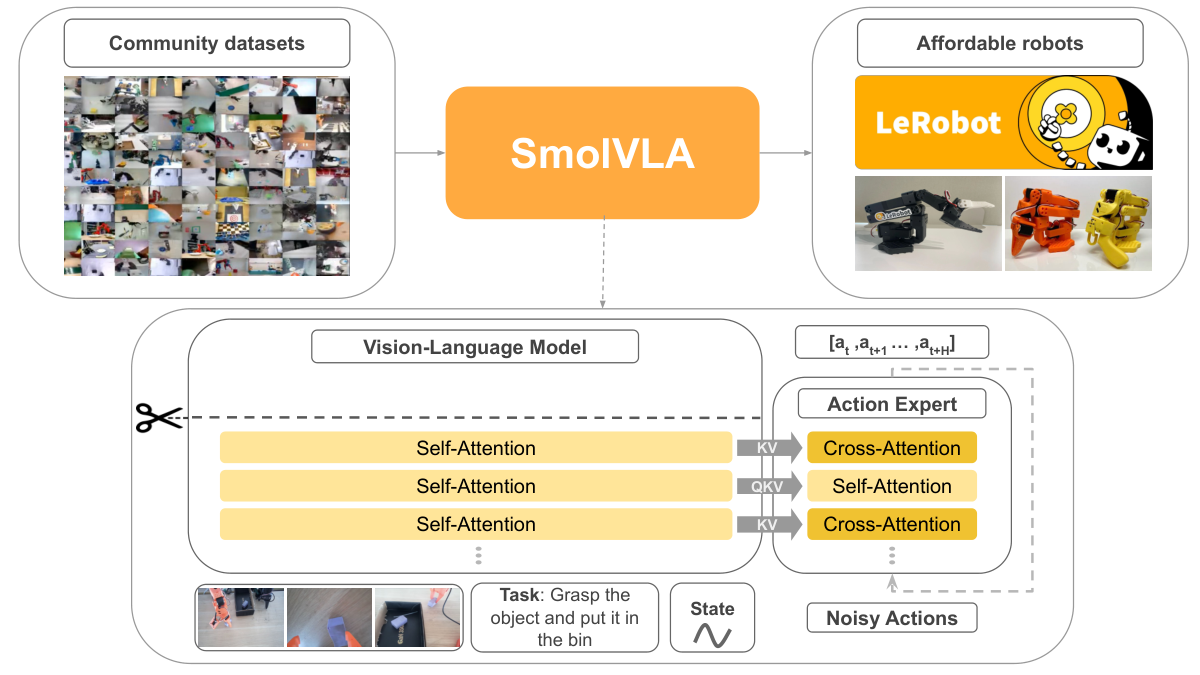

[SmolVLA, Figure 1](https://arxiv.org/html/2506.01844v1#S0.F1.fig1). Read the bottom half: the left tower is the VLM, and the right tower is the action expert. The top half summarises training data and deployment.

The paper trains a velocity field with

$$
\mathcal L^\tau(\theta)=
\mathbb E_{p(\mathbf A_t\mid\mathbf o_t),q(\mathbf A_t^\tau\mid\mathbf A_t)}
\left[\left\|\mathbf v_\theta(\mathbf A_t^\tau,\mathbf o_t)
-\mathbf u(\mathbf A_t^\tau\mid\mathbf A_t)\right\|^2\right].
$$

[Paper, §3.1](https://arxiv.org/html/2506.01844v1#S3.Ex1).
Here $\mathbf o_t$ contains camera images, the instruction, and robot state.
The experiment follows LeRobot's convention:
$\mathbf A^\tau=(1-\tau)\mathbf A+\tau\epsilon$,
$\mathbf u=\epsilon-\mathbf A$; sampling goes from $\tau=1$ to $0$.
The loss and solver are supplied.

## 1. Does the expert see the clean action label?

Use the trace table as a guide to Figure 1: **A–C** are the observation inputs,
**D** is their combined VLM prefix, **E** is the noisy-action input to the expert,
**F** is its predicted velocity, and **G** is the integrated action chunk.
Shapes list batch size, sequence length, and feature width; 32 action channels include padding for this six-channel robot.

Keep the observation and flow time fixed. Replace the clean action label by
$A'=A+\delta$, where the first action channel changes by 0.5 normalized units.
The supplied experiment compensates the noise so that the noisy input $A^\tau$ stays unchanged.

Run the experiment and identify which quantities changed: the expert's velocity, the target velocity, and the loss.
Explain the result using the two paths in the figure and the loss formula.
Show why different target velocities do not necessarily imply different losses.

The alternative label and compensated noise form a controlled probe, not a new dataset example or an independent Gaussian draw.

[`Source: training forward`](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/smolvla/modeling_smolvla.py#L762).

In [ ]:
smol = SmolExperiment()
chunk = smol.prediction_trace()
print('Action chunk:', tuple(chunk.shape))
smol.supervision_probe()

**Explanation:** …

## 2. When does the K/V cache pay off?

A cached forward first builds image/text/state K/V with the VLM (`prefill`),
then evaluates the expert using those K/V (`cached_velocity`).
A full forward rebuilds the prefix and evaluates the expert together (`recomputed_velocity`).
Both paths predict a new velocity for the same noisy action chunk and time;
**the cache stores observation features, not velocities**.

For one action chunk, let $P$ be the time to build the cache, $C$ one cached expert evaluation,
and $R$ one full forward. Approximate the costs of $N$ evaluations by
$$T_{\mathrm{cache}}(N)=P+NC,\qquad T_{\mathrm{full}}(N)=NR.$$

Use the timings to determine whether caching helps at $N=1$ and $N=10$ on your GPU.
Complete `first_faster_n`: return the smallest positive integer $N$ for which caching is faster,
or `None` if no such $N$ exists.

Run the timings and compare your threshold with the measured totals.
At $N=10$, would you prioritize reducing VLM prefix cost or cached expert cost? Support your choice with the timings.
Explain why the model's parameter count alone cannot answer this question.

The cell first checks velocity agreement. It then measures warmed-up, synchronized forwards,
using the same fixed observation and matched noisy inputs for both paths.
These probes exclude image capture and robot execution; they are not a policy-quality comparison.

In [ ]:
def first_faster_n(prefix_ms, cached_ms, full_ms):
    # TO DO: derive the first integer N satisfying P + N*C < N*R.
    raise NotImplementedError

In [ ]:
cached, recomputed, counts = smol.cache_comparison()
torch.testing.assert_close(cached, recomputed, rtol=1e-4, atol=1e-4)
print('Maximum velocity difference:', (cached - recomputed).abs().max().item())
P, C, R = smol.cache_latency_probe()
print('First faster N (cost model):', first_faster_n(P, C, R))
assert first_faster_n(12.0, 3.0, 7.0) == 4  # Equality at N=3 is not faster.
assert first_faster_n(12.0, 7.0, 3.0) is None

**Explanation:** …

## 3. Can you refresh only part of the prefix cache?

**Extension of standard SmolVLA.** In the LeRobot version used here,
[`sample_actions`](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/smolvla/modeling_smolvla.py#L820) builds the entire prefix cache
for each new action chunk and reuses it across that chunk's denoising steps.
It does not refresh state K/V separately. This question explores a possible extension.

A new robot-state reading arrives while images, instruction, and weights stay fixed.
An engineer proposes keeping image/text K/V and replacing only the state token's K/V.
Another proposes replacing state K/V only in the last layer.

Determine which proposal can reproduce a full prefix refresh.
Read the state-token attention rule in [`embed_prefix`](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/smolvla/modeling_smolvla.py#L692):
which tokens can read the state, and which can the state read?

Complete `patch_state_kv`: copy an old K/V tensor and replace just the state position
with the fresh value. K/V have shape `(batch, prefix positions, heads, head width)`.
Run the layer-by-layer comparison and the three velocity probes.

Explain which K/V must change and why refreshing only the last layer may fail.
Would your conclusion still hold if image/text tokens were allowed to attend to state?

The experiment computes a full fresh cache as a reference, then tests partial replacement.
It checks equivalence; it does not implement or time a faster state refresh.

In [ ]:
def patch_state_kv(old_kv, fresh_kv, state_position):
    # TO DO: replace only the state position without modifying old_kv.
    raise NotImplementedError

In [ ]:
stale, fresh = smol.partial_state_cache_probe(patch_state_kv)

**Explanation:** …

In [ ]:
# Release SmolVLA before the small π-model experiments.
del smol, chunk, cached, recomputed, stale, fresh
gc.collect()
if DEVICE.type == "cuda": torch.cuda.empty_cache()

# π₀

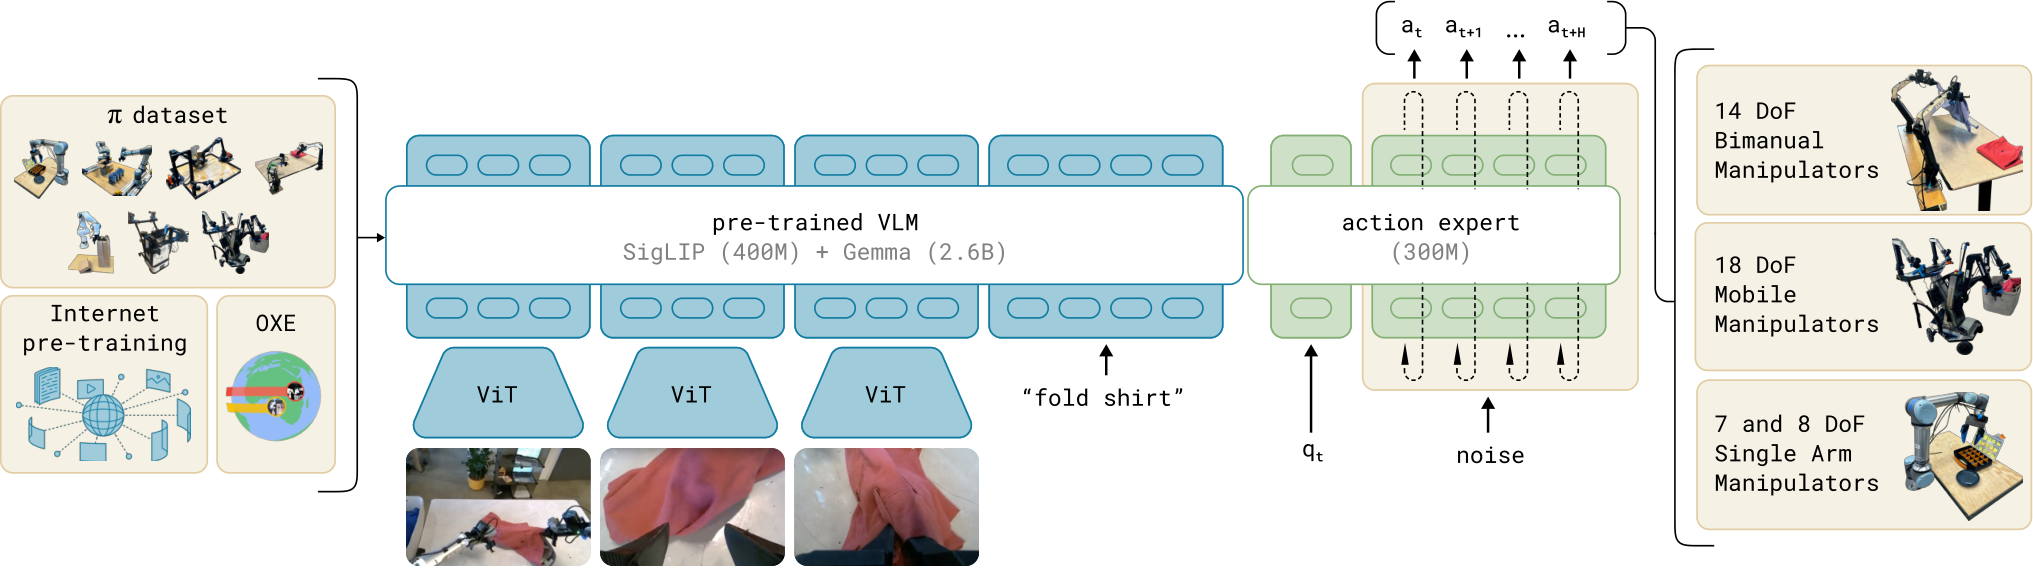

[π₀, Figure 3](https://arxiv.org/html/2410.24164v1#S2.F3). The pretrained VLM and action expert have separate parameters and communicate through attention.

The paper uses the same conditional velocity objective and integrates it with

$$
\mathbf A_t^{\tau+\delta}=\mathbf A_t^\tau+
\delta\,\mathbf v_\theta(\mathbf A_t^\tau,\mathbf o_t).
$$

[Paper, §IV](https://arxiv.org/html/2410.24164v1#S4.Ex2).
The next experiments execute the source's suffix construction and freeze rules
inside a small two-stream block. The image/text features and weights are small teaching substitutes.
LeRobot uses PyTorch. OpenPI provides the original JAX/Flax implementation and a PyTorch path.

## 4. Which tokens can influence each other in π₀ attention?

π₀ joins image/text tokens from the VLM with state and noisy-action tokens from the expert.
The experiment uses one small two-stream block with the source's attention mask.

Run the cell. In the mask plot, **rows are queries** and **columns are the K/V tokens they read**.
Change one state coordinate, then change only the **last** noisy action. The table measures
changes **after attention**, including the predicted velocity at the **first** action position.
Compare the π₀ mask with a modified mask that allows every token to read every other token.

Explain why the last noisy action can affect the first velocity while leaving VLM outputs unchanged
under the π₀ mask. What breaks if the VLM can read the changing noisy actions?
Use this to explain why π₀ can reuse VLM K/V during denoising despite performing joint attention.

Compare with SmolVLA: placing state in a different stream changes which weights process it;
it does not by itself prove different directions of information flow.

[`Mask construction`](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/pi0/modeling_pi0.py#L103) ·
[`State/action attention boundaries`](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/pi0/modeling_pi0.py#L680).

In [ ]:
show_source('modeling_pi0.py', 'make_att_2d_masks', max_lines=35)
attention_routing_probe()

**Explanation:** …

## 5. Can two separate attentions replace π₀ joint attention?

An engineer wants to replace π₀'s joint attention with two independent operations
for each action query: attention over **VLM K/V**, and attention over **expert K/V**
(state and noisy actions). They propose adding the two outputs.

The supplied code computes both separate outputs and the original joint output with identical
Q/K/V and masks. Run the comparison after completing the short TODO.

Each separate softmax normalizes its own group to sum to one. Joint attention instead normalizes
both groups together. Let $Z_{\mathrm{VLM}}$ and $Z_{\mathrm{expert}}$ be the sums of exponentiated
allowed scores in the two groups. Derive a mixing coefficient from these two masses;
use it to combine the separately normalized outputs and reproduce joint attention.

**Hint: what are Z and output?** For one action query $q$ (a row of $Q$),
each allowed key $k_j$ (a row of $K$) has score
$$s_j=\frac{q^\top k_j}{\sqrt{d_k}}.$$
For a group $G$ (VLM or expert),
$$Z_G=\sum_{j\in G\;\mathrm{allowed}} e^{s_j},\qquad
O_G=\sum_{j\in G\;\mathrm{allowed}}\frac{e^{s_j}}{Z_G}v_j.$$
**$O_G$ is the attention output vector for group $G$**: $O_{\mathrm{VLM}}$ is `vlm_output`,
and $O_{\mathrm{expert}}$ is `expert_output` for this query.
Here $v_j$ is the corresponding row of $V$. **Z is a scalar softmax denominator
for this query and group; output is a vector: the weighted average of that group's values.**
`vlm_output` and `expert_output` are these vectors for every action query;
`z_vlm` and `z_expert` are the matching denominators, with a final singleton dimension for broadcasting.
The code subtracts the same maximum score from both groups before exponentiating;
this rescales both Z values equally and leaves their relative weights unchanged.

Explain why a plain sum or a fixed 50/50 average changes the operation.
Use the per-query table to explain how an action query allocates attention between
perceptual context and state/action context, despite their separate projection weights.

[`π₀ joint attention`](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/pi0/modeling_pi0.py#L221).
The comparison uses a small random block and examines the attention output before its output projection.

In [ ]:
def mix_group_outputs(vlm_output, expert_output, z_vlm, z_expert):
    # TO DO: recover joint attention from the two normalized group outputs.
    raise NotImplementedError

In [ ]:
split_attention_probe(mix_group_outputs)
show_source('modeling_pi0.py', 'compute_layer_complete', max_lines=80)

**Explanation:** …

# π₀.₅

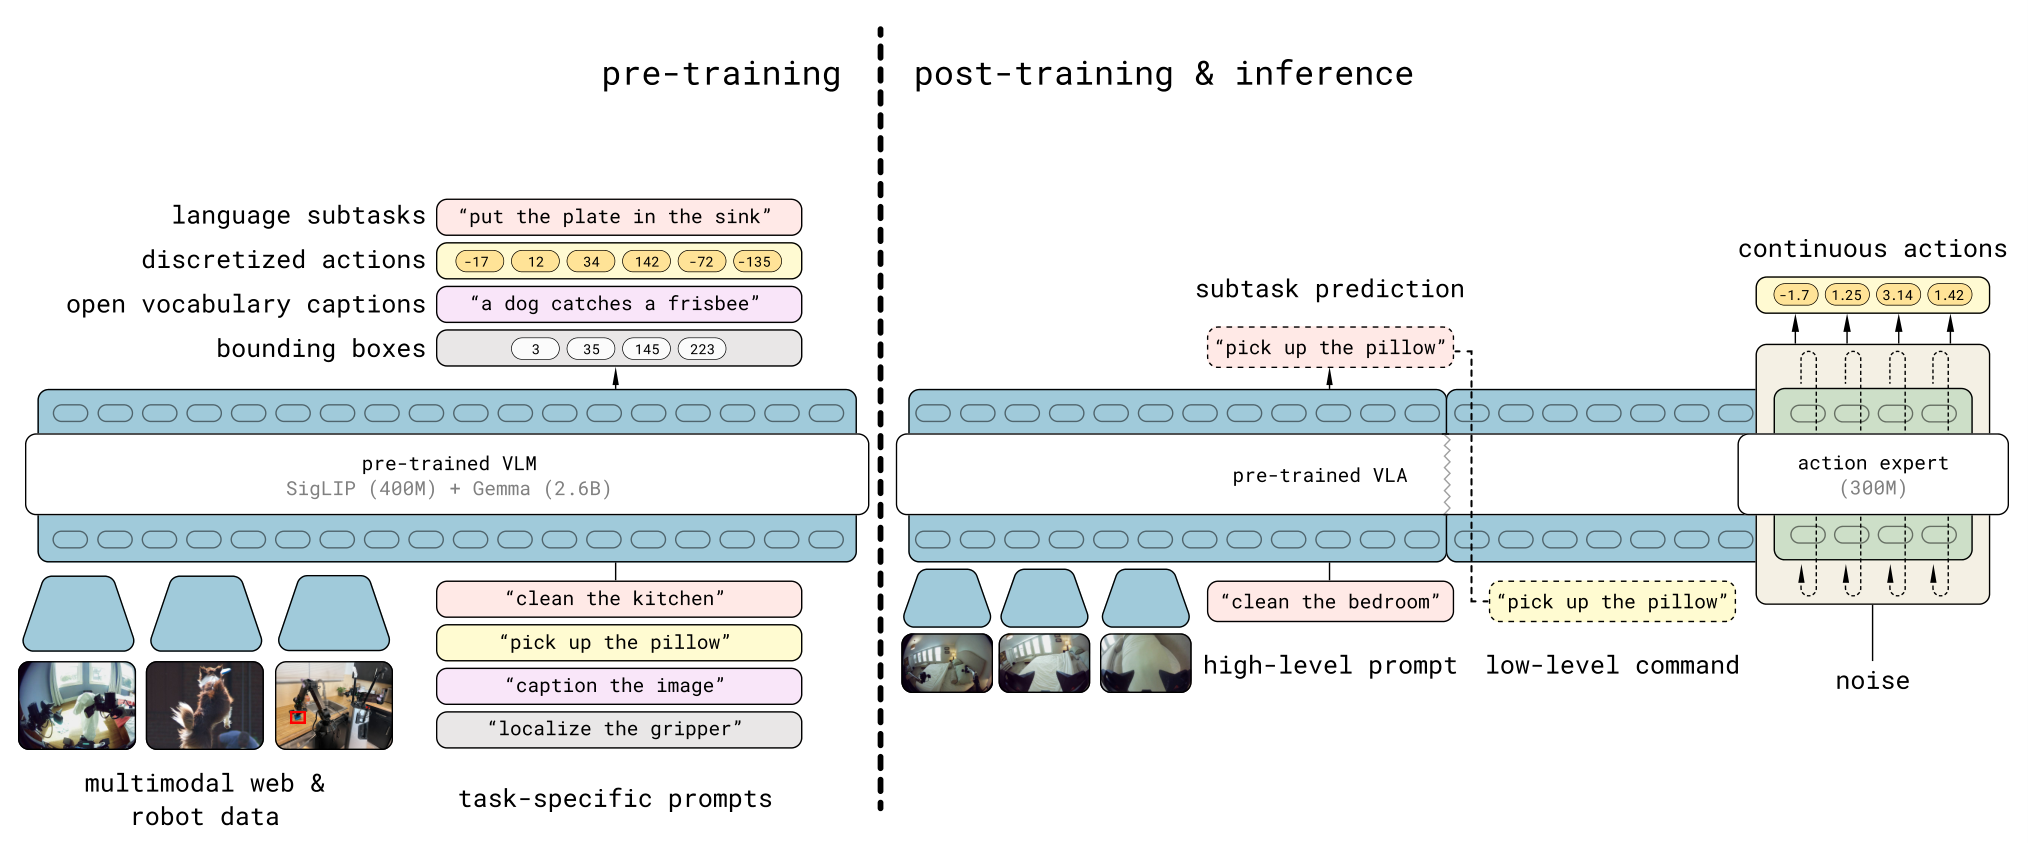

[π₀.₅, Figure 3](https://arxiv.org/html/2504.16054v1#S2.F3). The figure separates heterogeneous pretraining from post-training with continuous actions.

The paper combines token prediction with continuous flow matching:

$$
\mathbb E_{\mathcal D,\tau,\omega}\left[
H\!\left(x_{1:M},f_\theta^\ell(\mathbf o_t,\ell)\right)
+\alpha\left\|\omega-\mathbf a_{t:t+H}
-f_\theta^a(\mathbf a_{t:t+H}^{\tau,\omega},\mathbf o_t,\ell)\right\|^2\right].
$$

[Paper, Eq. (1)](https://arxiv.org/html/2504.16054v1#S4.EGx1).
The first $H(\cdot,\cdot)$ denotes cross-entropy; $\alpha$ weights the flow term.
The token targets depend on the training stage and example type.
For time conditioning, Appendix A-E gives

$$
c(\tau)=\operatorname{swish}\!\left(W_2\operatorname{swish}(W_1\phi(\tau))\right),
$$

where $\phi$ is sinusoidal encoding. This condition enters adaptive RMSNorm in each expert layer.
[Paper, Appendix A-E](https://arxiv.org/html/2504.16054v1#A1.SS5.p1).

## 6. Why does π₀.₅ tokenize state but use flow for actions?

π₀.₅ uses two different representations of sensorimotor numbers:
**normalized state is discretized into 256 bins and written into the VLM's text prompt**;
**the noisy action chunk stays continuous and enters the flow expert**.
The normal text tokenizer encodes the state numbers in the prompt; a bin index is not itself a vocabulary token ID.

Use this table to distinguish the paper's token-training paths from the released flow-action path:

| Representation | Role | Prediction target | Loss |
|---|---|---|---|
| Discretized state tokens | Input to the VLM prefix | No state-reconstruction target in the flow-action code | No direct state-token cross-entropy |
| Language / semantic tokens | Output of the paper's token-prediction path | Language / semantic token sequence | Cross-entropy |
| FAST action tokens | Output during discrete-action pretraining | Encoded demonstration actions | Cross-entropy |
| Continuous flow velocity | Output of the flow expert | $u=\epsilon-A$ | Squared velocity error |

Run the supplied experiment. Apply the same small scalar change separately to a state coordinate
and a noisy-action coordinate: first inside a state bin, then across a bin boundary.
Compare the state prompts and continuous action embeddings.

Explain why equally small state changes can be invisible or visible to the VLM,
while both changes reach the continuous action projection. Why does state tokenization
not make π₀.₅ a discrete-action policy?

**Does training explicitly teach the model to decode or reconstruct the state tokens?**
Read [`PI05Pytorch.forward`](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/pi05/modeling_pi05.py#L724): identify the prediction and target used by its loss.
Does reading state tokens imply that the model is trained to generate them?
What additional training target and loss would explicitly teach state-token decoding?

[`State prompt construction`](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/pi05/processor_pi05.py#L59) ·
[`Continuous action suffix`](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/pi05/modeling_pi05.py#L677).
The states are normalized teaching values; the action expert uses small random weights.

In [ ]:
show_source('processor_pi05.py', '__call__', 'Pi05PrepareStateTokenizerProcessorStep', max_lines=45)
discrete_state_continuous_action_probe()
show_source('modeling_pi05.py', 'forward', 'PI05Pytorch', max_lines=90)

**Explanation:** …

## Flow-time conditioning

Let $x_i^\tau$ be one position in the noisy action chunk and $\phi(\tau)$ the sinusoidal time embedding.

**π₀: time is fused into each action token before the expert layers.**
$$e_i=\operatorname{Linear}_{\mathrm{action}}(x_i^\tau),\qquad
h_i^{(0)}=\operatorname{Linear}_{\mathrm{out}}\!\left(
\operatorname{SiLU}\!\left(\operatorname{Linear}_{\mathrm{in}}
([e_i;\phi(\tau)] )\right)\right).$$
$[e_i;\phi(\tau)]$ means concatenation along the feature dimension; the same time embedding
is repeated at every action position. The two linear layers and SiLU are the action/time MLP
in [`π₀ embed_suffix`](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/pi0/modeling_pi0.py#L719).

**π₀.₅: action tokens and the time condition take separate paths.**
$$h_i^{(0)}=e_i,\qquad c(\tau)=\operatorname{MLP}_{\mathrm{time}}(\phi(\tau)).$$
The action projection does not mix in time. Instead, $c(\tau)$ modulates AdaRMS
inside the expert layers ([embedding code](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/pi05/modeling_pi05.py#L677),
[adaptive normalization code](https://github.com/huggingface/lerobot/blob/b9cb121cb7d4e3e26ec5c906d08dda68d151ba52/src/lerobot/policies/pi_gemma.py#L80)):
$$r=\frac{h}{\sqrt{\operatorname{mean}_D(h^2)+\varepsilon}},\qquad
(s,b,g)=\operatorname{split}(Wc(\tau)+d),\qquad
z=(1+s)\odot r+b.$$
Here $h$ is a hidden vector inside an expert layer, $s$ is adaptive scale, $b$ adaptive shift,
and $g$ the residual gate examined below. $z$ is the normalized, time-conditioned branch input.
For $h\in\mathbb R^{B\times T\times D}$ and $c\in\mathbb R^{B\times C}$,
scale, shift, and gate have shape $[B,1,D]$ and broadcast over token positions.
These formulas describe the pinned implementations; the paper's time MLP and conditioning
are discussed in [Appendix A-E](https://arxiv.org/html/2504.16054v1#A1.SS5.p1).

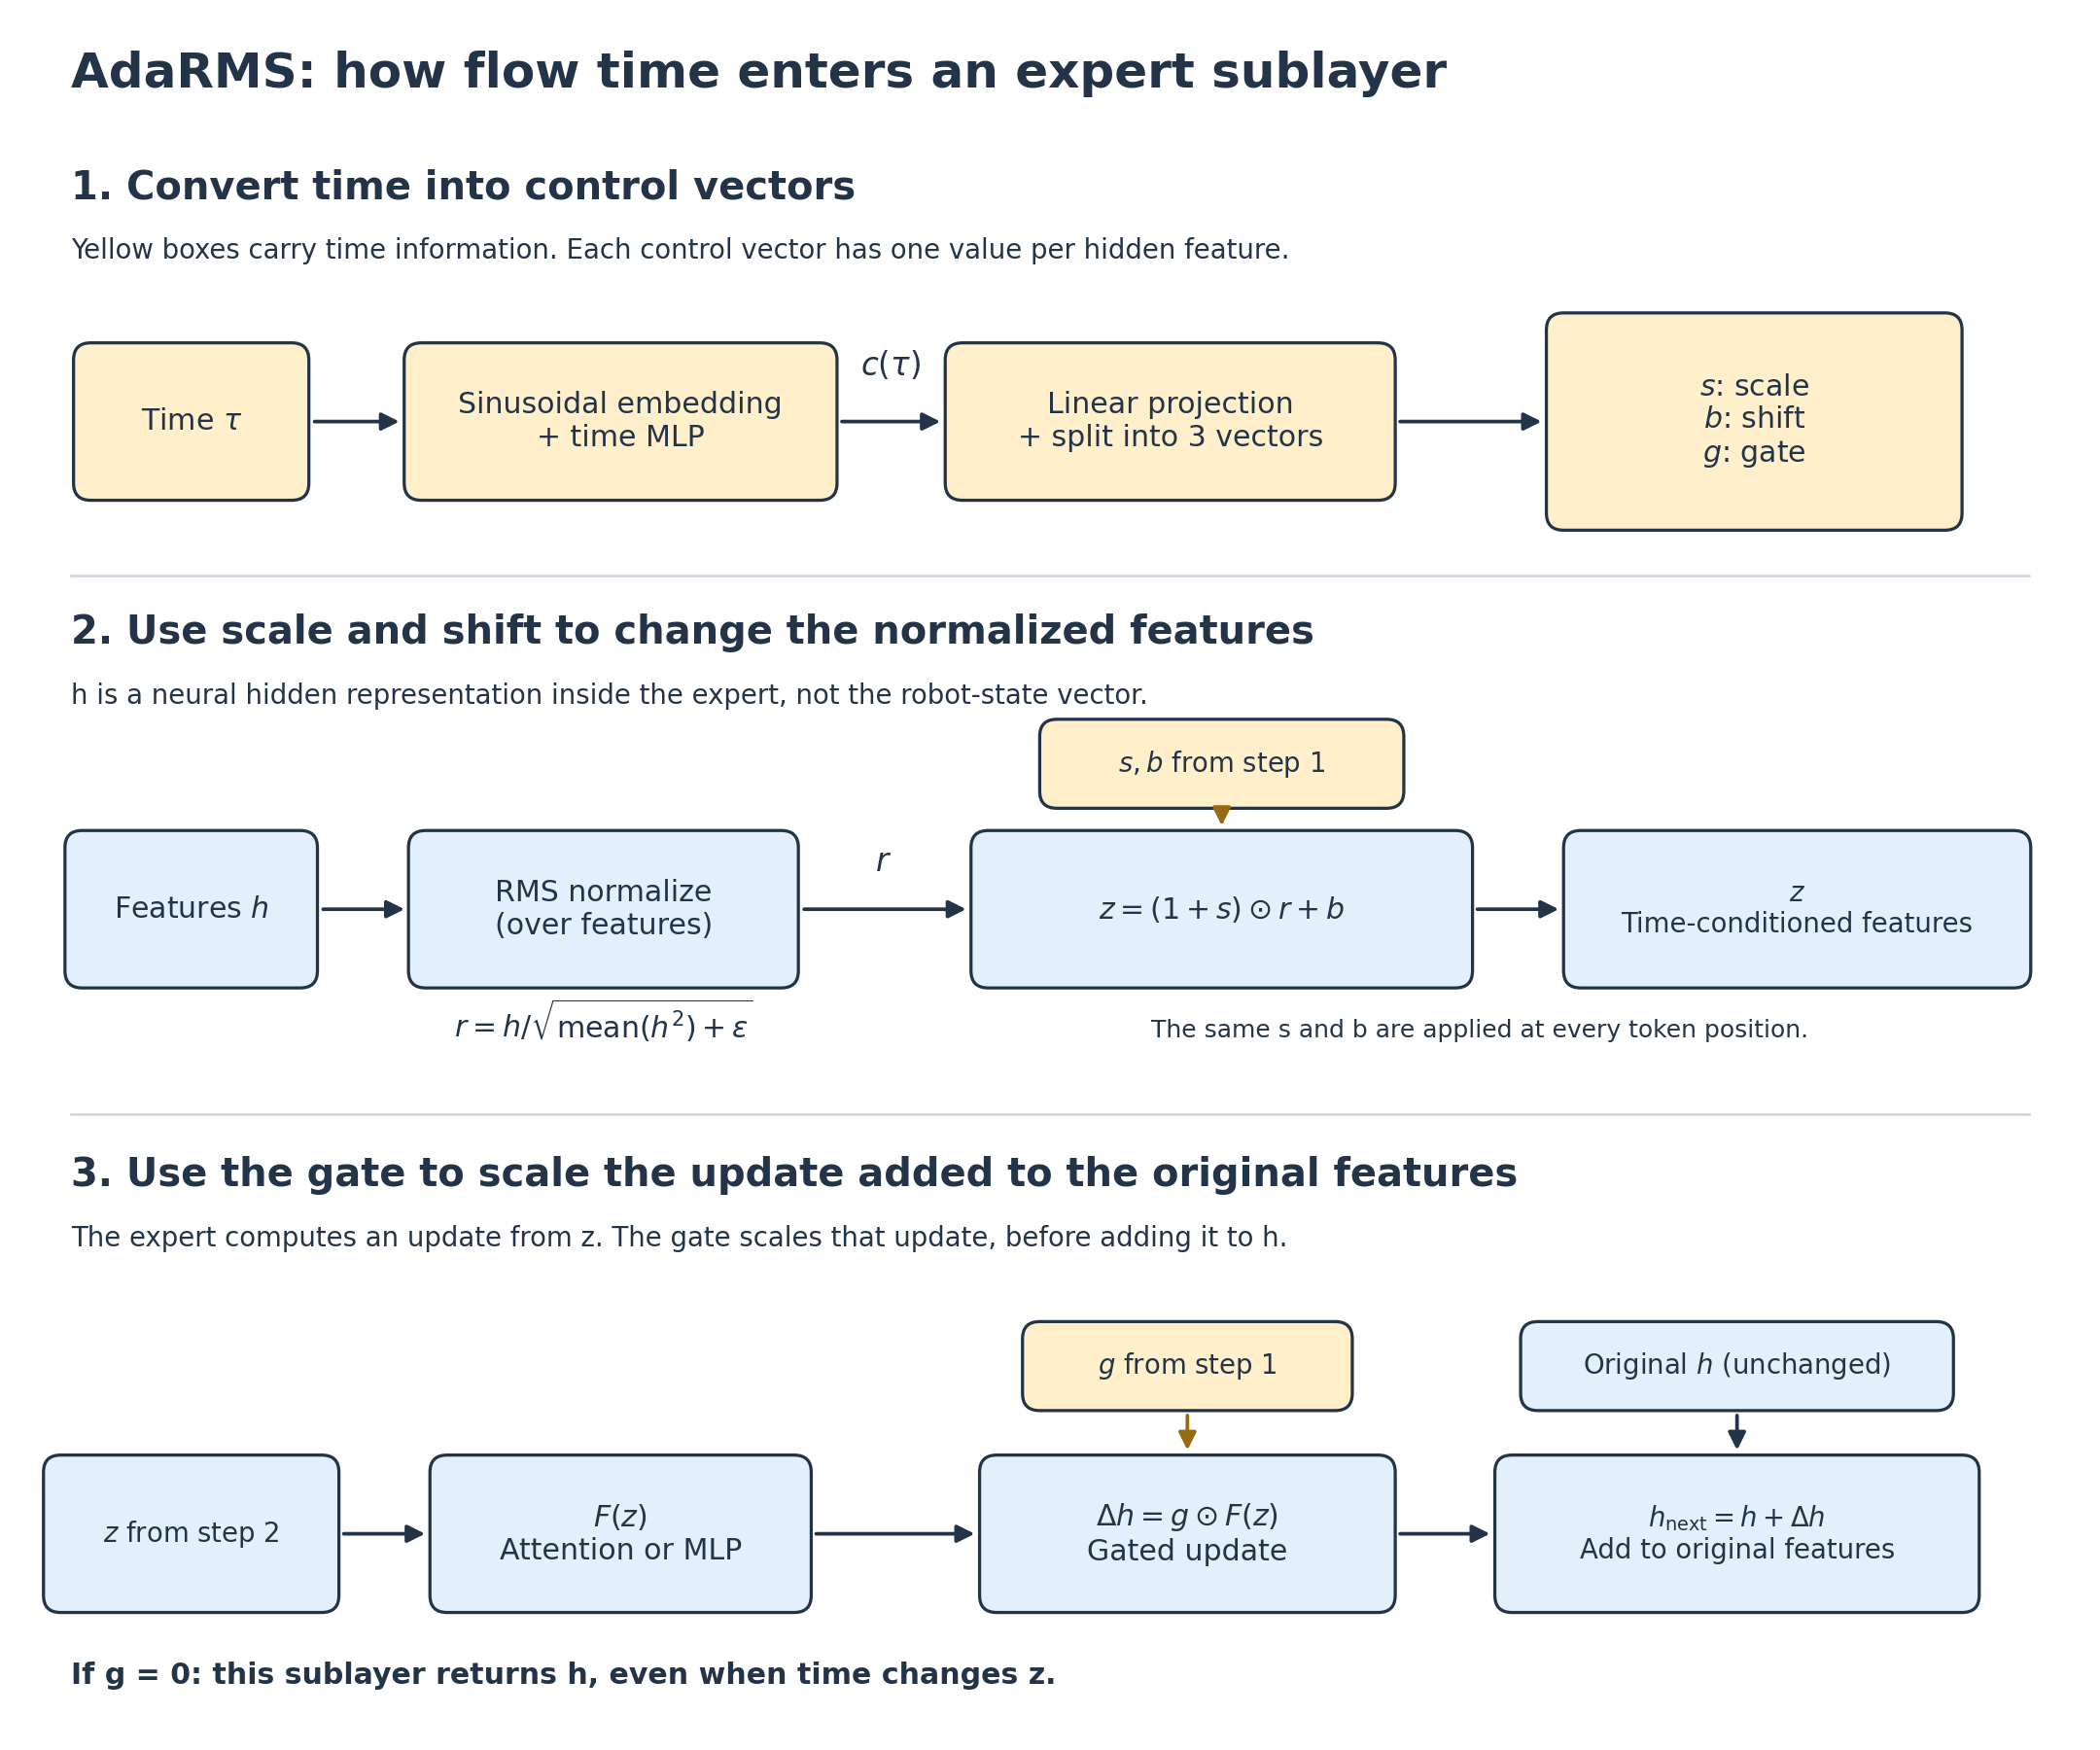

Teaching schematic based on [LeRobot's AdaRMS and gated residual implementation](https://github.com/huggingface/lerobot/blob/b9cb121cb7d4e3e26ec5c906d08dda68d151ba52/src/lerobot/policies/pi_gemma.py#L80),
not a figure from the π₀.₅ paper. Read the three steps from top to bottom:
time produces control vectors; scale/shift change the normalized features;
the gate scales the update added to the original features.
Here $h$ is a neural representation inside the expert, not the robot's sensorimotor state.
The diagram covers one attention or MLP sublayer; each has its own conditioning projection.

**Flow time** $\tau$ tells the expert where it is in the denoising process:
in our convention, $\tau=1$ starts from noise and $\tau=0$ ends at the action chunk.
It is not the robot's clock or a future action's position in the chunk.

The following experiments examine adaptive normalization and residual gating in π₀.₅.

## 7. Why can a fresh AdaRMS layer ignore different conditions?

Complete the conditional normalization formula.
The supplied π₀.₅ time MLP produces conditions for flow times 0.2 and 0.8. Keep hidden features h fixed.
Compare scale, shift, gate, and output for the two conditions at initialization.
Repeat with the supplied nonzero modulation weights. Explain the difference using the source.

In [ ]:
def conditional_norm(h, scale, shift, eps):
    # TO DO: RMS-normalize over features, then apply scale and shift.
    raise NotImplementedError

In [ ]:
condition_02, condition_08 = pi05_time_conditions()
show_source('pi_gemma.py', '__init__', 'PiGemmaRMSNorm')
adarms_values = adarms_probe(conditional_norm, (condition_02, condition_08))

**Explanation:** …

The residual gate is applied after the attention or MLP branch:

$$
h_{\mathrm{next}}=h+g\odot F(z).
$$

The adaptive scale and shift change the branch input; the gate controls how much of its output is added.

## 8. Can training open a branch blocked by a zero gate?

A zero gate gives $h_{\mathrm{next}}=h+g\odot F(z)=h$. Does this also prevent the gate from learning?

Complete the gated residual update. The experiment fixes $h$, the AdaRMS features $z$,
and a target different from $h$. It creates a **learnable gate initialized to zero** and a small linear branch $F$.

Run two backward passes: first at $g=0$, then after one optimizer update to **only the gate**.
Compare the gate gradient and branch-weight gradient in the table. The branch weights stay fixed;
only their gradients are measured.

Explain why the gate can receive a gradient while the branch weights initially receive zero gradient.
Why can the branch weights receive a gradient after the gate update? Derive the derivative of
$h_{\mathrm{next}}$ with respect to $g$ to support your explanation.

The zero gate is deliberately imposed for this experiment, not assumed to be π₀.₅'s default initialization.
In π₀.₅, a time-conditioned projection produces the gate; here it is a standalone parameter to isolate its role.

In [ ]:
def gated_update(residual, branch, gate):
    # TO DO: add the candidate update scaled by the learnable gate.
    raise NotImplementedError

In [ ]:
show_source('pi_gemma.py', '_gated_residual')
gate_results = gate_learning_probe(gated_update, condition_02)

**Explanation:** …

## References

- [SmolVLA paper](https://arxiv.org/abs/2506.01844), Figure 1 and §3.1.
- [π₀ paper](https://arxiv.org/abs/2410.24164), Figure 3 and §IV.
- [π₀.₅ paper](https://arxiv.org/abs/2504.16054), Figure 3, Eq. (1), Appendix A-E.
- [LeRobot SmolVLA](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/smolvla/modeling_smolvla.py) and [VLM/expert wiring](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/smolvla/smolvlm_with_expert.py).
- [LeRobot π₀](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/pi0/modeling_pi0.py), [π₀.₅](https://github.com/huggingface/lerobot/blob/8fff0fde7c79f23a93d845d1a50e985de01f8b8a/src/lerobot/policies/pi05/modeling_pi05.py), [AdaRMS](https://github.com/huggingface/lerobot/blob/b9cb121cb7d4e3e26ec5c906d08dda68d151ba52/src/lerobot/policies/pi_gemma.py).
- [SO100 pick-and-place data](https://huggingface.co/datasets/lerobot/svla_so100_pickplace/tree/728583b5eaf9e739a7f119e2def466fa1d552402).
- [Official SmolVLA training notebook](https://github.com/huggingface/notebooks/blob/main/lerobot/training-smolvla.ipynb).
- [OpenPI](https://github.com/Physical-Intelligence/openpi) and [LIBERO example](https://github.com/Physical-Intelligence/openpi/tree/main/examples/libero).

Paper figures © their original paper authors. LeRobot source excerpts and the dataset use Apache-2.0.